<a href="https://colab.research.google.com/github/Sahana14082003/AML/blob/main/Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Model Performance Comparison:
Activation Optimizer       Loss Function  Accuracy (%)
      ReLU      Adam Binary Crossentropy     94.736844
Leaky ReLU      Adam Binary Crossentropy     95.614034
      GELU      Adam Binary Crossentropy     95.614034
      Tanh      Adam Binary Crossentropy     96.491230
      ReLU       SGD Binary Crossentropy     93.859649
      ReLU      Adam Binary Crossentropy     95.614034
      ReLU   RMSprop Binary Crossentropy     97.368419
      ReLU      Adam binary_crossentropy     94.736844
      ReLU      Adam  mean_squared_error     97.368419


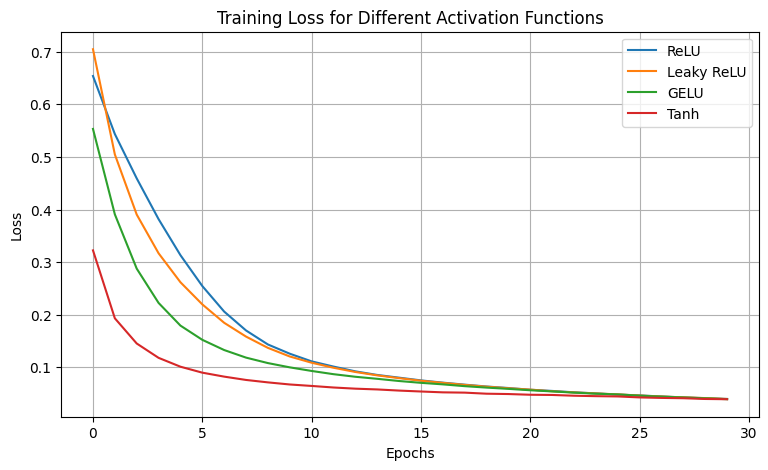

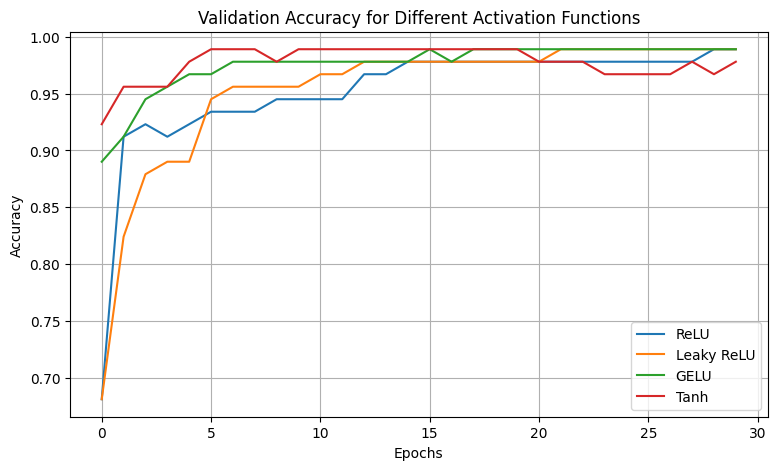

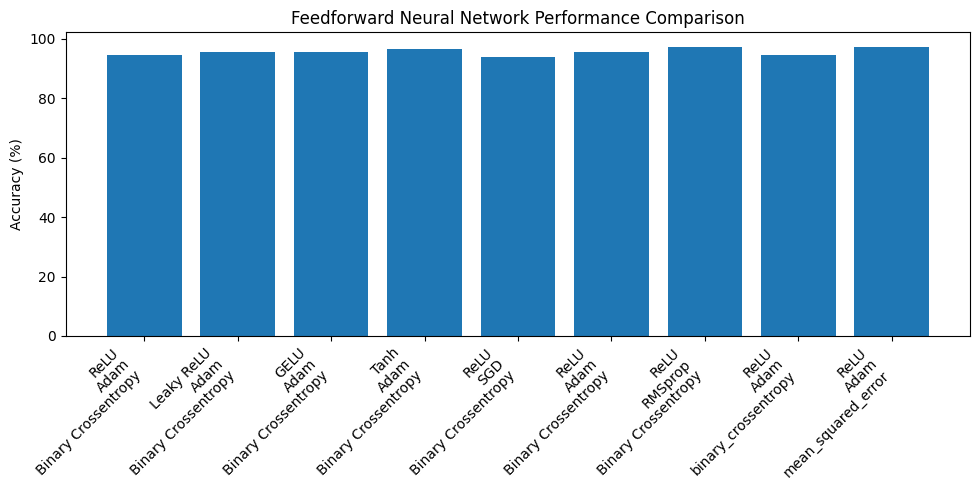

In [1]:

# 1. Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 2. Load Dataset
data = load_breast_cancer()
X = data.data
y = data.target

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Define Model
def build_model(activation, optimizer, loss):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(32, activation=activation),
        tf.keras.layers.Dense(16, activation=activation),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

# 6. Experiment with Activation Functions
activations = {
    'ReLU': tf.keras.layers.ReLU(),
    'Leaky ReLU': tf.keras.layers.LeakyReLU(negative_slope=0.01),
    'GELU': tf.keras.layers.Activation('gelu'),
    'Tanh': 'tanh'
}

results = []
histories = {}

for name, activation in activations.items():

    model = build_model(
        activation=activation,
        optimizer='adam',
        loss='binary_crossentropy'
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    results.append([name, 'Adam', 'Binary Crossentropy', accuracy * 100])
    histories[name] = history

# 7. Experiment with Optimizers
optimizers = ['SGD', 'Adam', 'RMSprop']

for opt in optimizers:

    model = build_model(
        activation='relu',
        optimizer=opt,
        loss='binary_crossentropy'
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    results.append(['ReLU', opt, 'Binary Crossentropy', accuracy * 100])

# 8. Experiment with Loss Functions
losses = ['binary_crossentropy', 'mean_squared_error']

for loss_fn in losses:

    model = build_model(
        activation='relu',
        optimizer='adam',
        loss=loss_fn
    )

    model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    results.append(['ReLU', 'Adam', loss_fn, accuracy * 100])

# 9. Display Comparison Results
result_df = pd.DataFrame(
    results,
    columns=['Activation', 'Optimizer', 'Loss Function', 'Accuracy (%)']
)

print("\nModel Performance Comparison:")
print(result_df.to_string(index=False))

# 10. Plot Training Loss
plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(history.history['loss'], label=name)

plt.title('Training Loss for Different Activation Functions')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 11. Plot Validation Accuracy
plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(history.history['val_accuracy'], label=name)

plt.title('Validation Accuracy for Different Activation Functions')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 12. Plot Accuracy Comparison
plt.figure(figsize=(10, 5))
plt.bar(
    range(len(result_df)),
    result_df['Accuracy (%)']
)
plt.xticks(
    range(len(result_df)),
    [f"{r.Activation}\n{r.Optimizer}\n{r._3}" for r in result_df.itertuples()],
    rotation=45,
    ha='right'
)
plt.ylabel('Accuracy (%)')
plt.title('Feedforward Neural Network Performance Comparison')
plt.tight_layout()
plt.show()
